In [1]:
import numpy as np
from pathlib import Path
import pandas as pd
from sklearn.model_selection import train_test_split

DATA = Path("../data")

df = pd.read_csv(DATA / 'ml_sessions.csv')

In [2]:
done = df[df['failed'] == 0]                # Completed sessions only

numeric = [
    'station_age_years', 'power_kw', 'num_bays', 'hour',
    'day_of_week', 'is_weekend', 'ambient_temp_c', 'grid_load_index',
    'start_soc_pct', 'battery_capacity_kwh'
]

categorical = ['connector_type', 'zone', 'vehicle_segment']

print(len(done), "Completed sessions")
print(done['energy_kwh'].describe().T.round(3))

41199 Completed sessions
count    41199.000
mean        10.534
std         24.898
min          0.020
25%          0.810
50%          2.140
75%         11.830
max        857.630
Name: energy_kwh, dtype: float64


## Let's inspect the target

In [3]:
impossible_values = done['energy_kwh'] > done['battery_capacity_kwh']

print("sessions delivering more than the battery capacity: ", impossible_values.sum())


sessions delivering more than the battery capacity:  450


In [4]:
print(done.loc[impossible_values, ['vehicle_segment', 'battery_capacity_kwh', 'energy_kwh']].head(4))

    vehicle_segment  battery_capacity_kwh  energy_kwh
100              4W                  57.4      115.96
116              3W                   6.5       18.64
215              4W                  29.6       57.14
349              3W                  11.8       21.07


## Regression metrics and baseline

In [5]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error

X, y = done[numeric + categorical], done['energy_kwh']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.25, random_state = 42)

dummy = DummyRegressor()

dummy.fit(X_train, y_train)

y_pred = dummy.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)

rmse = root_mean_squared_error(y_test, y_pred)

r2 = r2_score(y_test, y_pred)

print("mae     : ", mae)
print("rmse    : ", rmse)
print("R2 score: ", r2)

mae     :  12.077065498050805
rmse    :  24.46039127700056
R2 score:  -6.90371059741679e-06


In [6]:
def report(model, y_test, y_pred):
    print(f"{model:28} \nMAE {mean_absolute_error(y_test, y_pred):6.2f}"
          f"\nRMSE {root_mean_squared_error(y_test, y_pred):6.2f}"
          f"\nR2 {r2_score(y_test, y_pred):6.3f}")

In [7]:
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

ok_train = ~impossible_values.loc[X_train.index]
ok_test = ~impossible_values.loc[X_test.index]
one = ['battery_capacity_kwh']

line = LinearRegression().fit(X_train.loc[ok_train, one], y_train[ok_train])
print(f"slope {line.coef_[0]:.6f} KWh per KwH of battery     intercept: {line.intercept_:.3f} KwH")


report("Linear regression: one column feature", y_test[ok_test], line.predict(X_test.loc[ok_test, one]))

slope 0.243841 KWh per KwH of battery     intercept: 1.089 KwH
Linear regression: one column feature 
MAE   4.81
RMSE  10.90
R2  0.670


In [8]:
impossible_values.sum()

np.int64(450)

In [9]:
X_train.index

Index([19955, 37808, 34601,  8534, 18936, 29748, 15555, 43949, 12435, 19025,
       ...
       44884, 17526, 24027, 40637, 18449,  6843, 12347, 41668,   933, 17280],
      dtype='int64', length=30899)

In [10]:
df['battery_capacity_kwh'].min()

np.float64(2.0)

In [11]:
df['battery_capacity_kwh'].max()

np.float64(349.8)

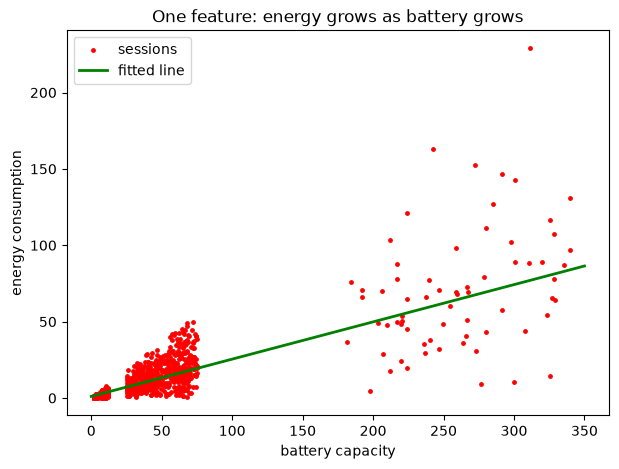

In [12]:
sample = X_train.loc[ok_train].sample(1500, random_state = 42)

xs = pd.DataFrame({'battery_capacity_kwh': [0, 350]})

plt.figure(figsize = (7, 5))
plt.scatter(sample['battery_capacity_kwh'], y_train[sample.index], s=6, color = 'red', label = 'sessions')
plt.plot(xs['battery_capacity_kwh'], line.predict(xs), color = 'green', lw = 2, label = 'fitted line')
plt.xlabel('battery capacity')
plt.ylabel('energy consumption')
plt.title("One feature: energy grows as battery grows")
plt.legend()
plt.show()

## Linear regression on the raw target

In [13]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

def prep():
    return ColumnTransformer([
        ('num', StandardScaler(), numeric),
        ("cat", OneHotEncoder(handle_unknown = 'ignore'), categorical),
    ])


dirty_model = make_pipeline(prep(), LinearRegression()).fit(X_train, y_train)

def report(model, y_test, y_pred):
    print(f"{model:28} \nMAE {mean_absolute_error(y_test, y_pred):6.2f}"
          f"\nRMSE {root_mean_squared_error(y_test, y_pred):6.2f}"
          f"\nR2 {r2_score(y_test, y_pred):6.3f}")

report("linear regression", y_test, dirty_model.predict(X_test))

linear regression            
MAE   5.85
RMSE  17.63
R2  0.481


## mae     :  12.077065498050805
rmse    :  24.46039127700056
R2 score:  -6.90371059741679e-06

In [15]:
bad_test = y_test > X_test['battery_capacity_kwh']
bad_train = y_train > X_train['battery_capacity_kwh']

clean_model = make_pipeline(prep(), LinearRegression()).fit(X_train[~bad_train], y_train[~bad_train])

report("LinearRegression: cleaned", y_test[~bad_test], clean_model.predict(X_test[~bad_test]))

LinearRegression: cleaned    
MAE   5.10
RMSE  10.42
R2  0.698


In [16]:
clean = done[~impossible_values]
Xc, yc = clean[numeric + categorical], clean['energy_kwh']

Xc_train, Xc_test, yc_train, yc_test = train_test_split(Xc, yc, test_size = 0.25, random_state = 42)

clean_model = make_pipeline(prep(), LinearRegression()).fit(Xc_train, yc_train)

report("Cleaned data from here on", yc_test, clean_model.predict(Xc_test))

Cleaned data from here on    
MAE   5.14
RMSE  10.51
R2  0.697


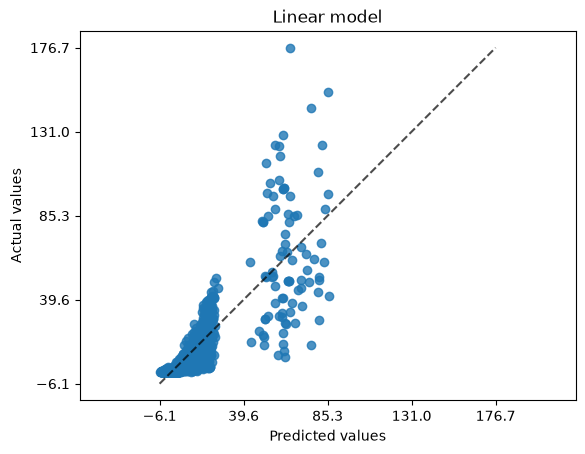

In [17]:
from sklearn.metrics import PredictionErrorDisplay

PredictionErrorDisplay.from_predictions(
    yc_test, clean_model.predict(Xc_test), kind = "actual_vs_predicted",
    subsample = 1500, random_state = 42)
plt.title("Linear model")
plt.show()

## Lasso

In [18]:
from sklearn.linear_model import Lasso

lasso = make_pipeline(prep(), Lasso(alpha=0.5)).fit(Xc_train, yc_train)

names = lasso[:-1].get_feature_names_out()
kept = names[lasso[-1].coef_!=0]

report("lasso alpha = 0.5", yc_test, lasso.predict(Xc_test))
print(f" Kept {len(kept)} of {len(names)} features")
print(list(kept))

lasso alpha = 0.5            
MAE   4.97
RMSE  10.65
R2  0.689
 Kept 5 of 25 features
['num__power_kw', 'num__num_bays', 'num__start_soc_pct', 'num__battery_capacity_kwh', 'cat__vehicle_segment_4W']


## Ridge

In [19]:
from sklearn.linear_model import Ridge
from sklearn.preprocessing import PolynomialFeatures

def poly_prep():
    return ColumnTransformer([
        ('num', make_pipeline(StandardScaler(), PolynomialFeatures(2, include_bias=False)), numeric),
        ("cat", OneHotEncoder(handle_unknown='ignore'), categorical)
    ])

few_X, few_y = Xc_train.iloc[:150], yc_train.iloc[:150]
plain = make_pipeline(poly_prep(), LinearRegression()).fit(few_X, few_y)

print("rows: ", len(few_X), "  Columns aftter polynomial features: ", plain[:-1].transform(few_X).shape[1])
report("150 rows, plain linear", yc_test, plain.predict(Xc_test))

rows:  150   Columns aftter polynomial features:  80
150 rows, plain linear       
MAE   8.15
RMSE  17.92
R2  0.119


In [20]:
Xc_train.shape

(30561, 13)

In [22]:
from sklearn.model_selection import cross_val_score

cv_rmse = {}
alpha_values = [0.1, 1, 10, 100, 1000]

for alpha in alpha_values:
    candidate = make_pipeline(poly_prep(), Ridge(alpha=alpha))
    scores = cross_val_score(candidate, few_X, few_y, cv=5, scoring = 'neg_root_mean_squared_error')
    cv_rmse[alpha] = -scores.mean()
    print(f"alpha {alpha}      CV RMSE  {cv_rmse[alpha]:.2f}")

best_alpha=min(cv_rmse, key = cv_rmse.get)
ridge = make_pipeline(poly_prep(), Ridge(alpha=best_alpha)).fit(few_X, few_y)
report(f"150 rows, Ridge alha = {best_alpha}", yc_test, ridge.predict(Xc_test))


alpha 0.1      CV RMSE  17.43
alpha 1      CV RMSE  15.64
alpha 10      CV RMSE  13.22
alpha 100      CV RMSE  11.76
alpha 1000      CV RMSE  12.45
150 rows, Ridge alha = 100   
MAE   6.37
RMSE  12.07
R2  0.601


## Skewed target: How do we handle it 


(array([4.044e+04, 6.730e+02, 5.900e+01, 0.000e+00, 4.000e+00, 5.000e+00,
        8.000e+00, 3.000e+00, 5.000e+00, 2.000e+00]),
 array([2.00000e-02, 8.57810e+01, 1.71542e+02, 2.57303e+02, 3.43064e+02,
        4.28825e+02, 5.14586e+02, 6.00347e+02, 6.86108e+02, 7.71869e+02,
        8.57630e+02]),
 <BarContainer object of 10 artists>)

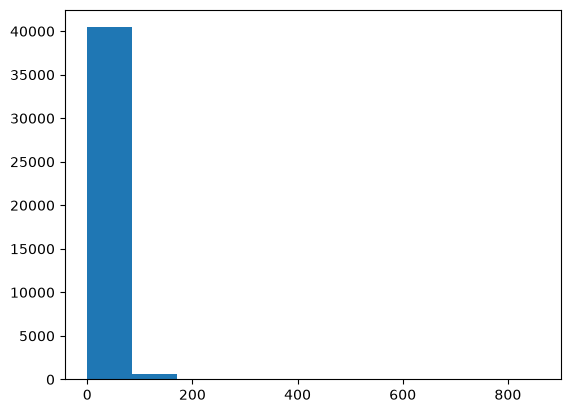

In [29]:
plt.hist(df[df['energy_kwh'] != 0]['energy_kwh'], bins = 10)

(array([  151.,  1044.,  4707., 10658.,  8145.,  6332.,  7551.,  2087.,
          497.,    27.]),
 array([-3.91202301, -2.84540343, -1.77878385, -0.71216427,  0.35445531,
         1.42107488,  2.48769446,  3.55431404,  4.62093362,  5.68755319,
         6.75417277]),
 <BarContainer object of 10 artists>)

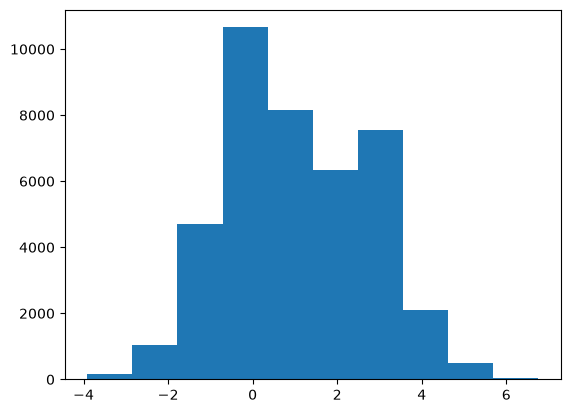

In [28]:
plt.hist(np.log(df[df['energy_kwh'] != 0]['energy_kwh']), bins = 10)

In [35]:
from sklearn.compose import TransformedTargetRegressor
from sklearn.metrics import mean_absolute_error

log_model = TransformedTargetRegressor(
    regressor=make_pipeline(poly_prep(), LinearRegression()),
    func = np.log1p, inverse_func=np.expm1,
).fit(Xc_train, yc_train)

for name, m in [("raw_target", clean_model), ("log_target", log_model)]:
    p = m.predict(Xc_test)
    print(f"{name} median error {mean_absolute_error(yc_test, p):.2f}  "
          f" R2 {r2_score(yc_test, p):.3f}"
          f" RMSE {root_mean_squared_error(yc_test, p):.2f}")



raw_target median error 5.14   R2 0.697 RMSE 10.51
log_target median error 3.86   R2 0.754 RMSE 9.46


## Exercises

1. Try lasso(alpha = 0.1). See how many coefficients survive ?

2. Repeat the 150 rows experiment change the value to 1500 rows . See which is better Ridge or Lasso ?

3. Remove duration_mins from the features. Check whether R2 score falls and if so why is is falling ?